# Model Evaluation

This notebook evaluates the five credit risk models of the project and compares the current version (**v2**) with the previous one (**v1**).

It only **loads and evaluates** saved artifacts: the preprocessors and trained models (`models/`) and the calibrated models (`calibration/`). Nothing is trained, calibrated or overwritten, so anyone who clones the repository can run it and get the same numbers.

The artifacts are produced by the scripts, in this order:
1. `python -m src.processing`: fits and saves the preprocessors.
2. `python -m src.modeling`: trains the models.
3. `python -m src.calibration`: calibrates the models.

**Steps:**
1. Data: the role of each set
2. Discrimination: how well the models rank customers by risk
3. v1 × v2: effect of the new preprocessing
4. Calibration: can the predicted probabilities be read as PDs?
5. v1 × v2 after calibration
6. Conclusions

In [1]:
# Automatically reload modules from src/ when their code changes,
# without restarting the kernel.
%load_ext autoreload
%autoreload 2

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import (
    X_TRAIN_DIR, Y_TRAIN_DIR,
    X_VAL_DIR, Y_VAL_DIR,
    X_TEST_DIR, Y_TEST_DIR,
    MODELS, MODELS_CALIBRATED, METRICS_DIR,
)
from src.processing import process_data
from src.evaluation import evaluate_model, get_metrics
from src.calibration import evaluate_calibration

## Parameters

- `FOCUS_MODEL`: model used for the detailed calibration plots (section 4). It must be one of the keys of `MODELS` in `src/config.py`.
- `V1_METRICS_DIR`: folder with the v1 reference metrics, stored from the `v1-baseline` git tag.

In [2]:
FOCUS_MODEL = "lightgbm"
V1_METRICS_DIR = METRICS_DIR / "v1"

print("Available models:", list(MODELS.keys()))

Available models: ['log_reg', 'random_forest', 'catboost', 'xgboost', 'lightgbm']


## 1. Data

The data was split once, stratified by the target, into three sets with different roles:

- **Train**: fits the preprocessors (medians, scaler) and the models.
- **Validation**: compares the models and fits the calibration.
- **Test**: kept aside for the final numbers. Since the calibration is fitted on validation, the calibrated models are evaluated on test.

All sets are indexed by the customer `ID`, which keeps features and target aligned.

In [3]:
def load_set(x_path, y_path):
    """Loads the features (10 original columns) and the target, indexed by ID."""
    X = pd.read_csv(x_path, index_col="ID")
    y = pd.read_csv(y_path, index_col="ID").squeeze("columns")
    assert X.index.equals(y.index), "X and y indexes do not match!"
    return X, y

X_train, y_train = load_set(X_TRAIN_DIR, Y_TRAIN_DIR)
X_val, y_val = load_set(X_VAL_DIR, Y_VAL_DIR)
X_test, y_test = load_set(X_TEST_DIR, Y_TEST_DIR)

sets_summary = pd.DataFrame(
    {
        "rows": [len(y_train), len(y_val), len(y_test)],
        "default rate (%)": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
    },
    index=["train", "validation", "test"],
)
sets_summary.round(2)

,rows,default rate (%)
train,105000,6.68
validation,22500,6.68
test,22500,6.68


The default rate is 6.68% in all three sets, as expected from a stratified split. The data is **imbalanced**: only about 1 in 15 customers defaults.

## 2. Discrimination

Discrimination is the ability to **rank** customers: defaulters should get higher scores than non-defaulters.

- **ROC-AUC**: probability that a random defaulter gets a higher score than a random non-defaulter (0.5 = random, 1 = perfect).
- **KS** (Kolmogorov-Smirnov): maximum distance between the score distributions of defaulters and non-defaulters. Standard in the credit market.
- **Gini**: `2 × AUC − 1`, a rescaled AUC common in risk reports.
- **Brier score**: mean squared error of the predicted probabilities. It is high here on purpose (see section 4), so it is only compared after calibration.

`get_metrics` (from `src.evaluation`) applies each model's preprocessor and evaluates the saved model.

In [4]:
train_metrics = get_metrics(X_train, y_train)
val_metrics = get_metrics(X_val, y_val)

val_metrics.set_index("Model").round(4)

,ROC-AUC,KS,Gini,Brier score
Model,,,,
Logistic Regression,0.8625,0.5778,0.7250,0.1437
Random Forest,0.8684,0.5845,0.7369,0.1331
CatBoost,0.8710,0.5906,0.7420,0.1357
XGBoost,0.8698,0.5846,0.7396,0.1372
LightGBM,0.8711,0.5887,0.7422,0.1393


Reproducibility check: the numbers must match the ones saved by `python -m src.evaluation`.

In [5]:
saved = pd.read_csv(METRICS_DIR / "validation_metrics.csv").set_index("Model")
computed = val_metrics.set_index("Model")
cols = ["ROC-AUC", "KS", "Gini", "Brier score"]

assert np.allclose(saved.loc[computed.index, cols], computed[cols]), "Metrics differ from the saved CSV"
print("Validation metrics match reports/metrics/validation_metrics.csv")

Validation metrics match reports/metrics/validation_metrics.csv


### Overfitting

A model that memorizes the training data scores much better on train than on validation. The drop from train to validation measures this.

In [6]:
overfit = pd.DataFrame(
    {
        "AUC train": train_metrics["ROC-AUC"].values,
        "AUC validation": val_metrics["ROC-AUC"].values,
        "KS train": train_metrics["KS"].values,
        "KS validation": val_metrics["KS"].values,
    },
    index=val_metrics["Model"],
)
overfit["AUC drop"] = overfit["AUC train"] - overfit["AUC validation"]
overfit["KS drop"] = overfit["KS train"] - overfit["KS validation"]

overfit.round(4)

,AUC train,AUC validation,KS train,KS validation,AUC drop,KS drop
Model,,,,,,
Logistic Regression,0.8576,0.8625,0.5557,0.5778,-0.0049,-0.0220
Random Forest,0.8943,0.8684,0.6286,0.5845,0.0259,0.0442
CatBoost,0.8907,0.8710,0.6204,0.5906,0.0196,0.0297
XGBoost,0.8882,0.8698,0.6127,0.5846,0.0184,0.0281
LightGBM,0.8824,0.8711,0.6028,0.5887,0.0113,0.0141


**Reading:**

- The four ensembles are practically tied on validation (AUC ≈ 0.87). Their differences are within the normal variation between samples.
- Random Forest has the largest drop from train to validation (≈ 0.026 AUC): it overfits the most. LightGBM is the most stable.
- Logistic Regression scores slightly higher on validation than on train. A linear model has little capacity to memorize, and a difference this small is just sampling variation.

## 3. v1 × v2: effect of the new preprocessing

The v2 preprocessing applies the treatments decided in the EDA (`src/feature_creation.py`):

- **Codes 96/98** in the late-payment counts are not real counts: they become missing and receive the median (0). Flag: `SpecialCode`.
- **Util > 10** is a data error: it becomes missing and receives the median of Util. Flag: `UtilInvalid`.
- **No usable income** (missing, 0 or 1): in these rows `Debt` holds the debt amount instead of the debt-to-income ratio, so it receives the median ratio. Flag: `IncomeMissing`.

The hyperparameters did not change, so any difference in the metrics comes only from the preprocessing. The v1 metrics were stored in `reports/metrics/v1/` from the `v1-baseline` git tag.

In [7]:
v1_val = pd.read_csv(V1_METRICS_DIR / "validation_metrics.csv")

def compare_versions(v1, v2, metrics):
    """Puts v1 and v2 side by side, with the difference (v2 - v1), for each model."""
    v1 = v1.set_index("Model")
    v2 = v2.set_index("Model")
    table = {}
    for metric in metrics:
        table[(metric, "v1")] = v1[metric]
        table[(metric, "v2")] = v2[metric]
        table[(metric, "v2 - v1")] = v2[metric] - v1[metric]
    return pd.DataFrame(table)

compare_versions(v1_val, val_metrics, ["ROC-AUC", "KS"]).round(4)

ROC-AUC                      KS                
                         v1      v2 v2 - v1      v1      v2 v2 - v1
Model                                                              
Logistic Regression  0.8225  0.8625  0.0400  0.5349  0.5778  0.0429
Random Forest        0.8688  0.8684 -0.0004  0.5828  0.5845  0.0016
CatBoost             0.8701  0.8710  0.0009  0.5839  0.5906  0.0067
XGBoost              0.8700  0.8698 -0.0001  0.5848  0.5846 -0.0002
LightGBM             0.8708  0.8711  0.0003  0.5872  0.5887  0.0015

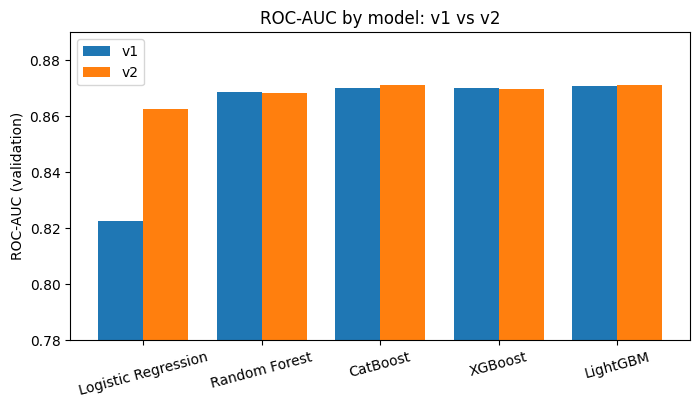

In [8]:
comparison = compare_versions(v1_val, val_metrics, ["ROC-AUC"])
x = np.arange(len(comparison))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - width / 2, comparison[("ROC-AUC", "v1")], width, label="v1")
ax.bar(x + width / 2, comparison[("ROC-AUC", "v2")], width, label="v2")
ax.set_xticks(x)
ax.set_xticklabels(comparison.index, rotation=15)
# The axis starts at 0.78 (not 0) to make the differences visible
ax.set_ylim(0.78, 0.89)
ax.set_ylabel("ROC-AUC (validation)")
ax.set_title("ROC-AUC by model: v1 vs v2")
ax.legend()
plt.show()

**Reading:**

- **Logistic Regression gains about 0.04 in AUC and KS.** Its distance to the best ensemble falls from about 0.048 to about 0.009 AUC.
- **The ensembles do not change**: the differences are within the normal variation between samples.

Why: tree models isolate extreme values with splits, so codes 96/98, Util in the thousands or Debt amounts did not hurt them. A linear model cannot do that: these values distorted the standardization and forced a single linear effect over values with different meanings. The EDA treatments remove the distortion, and the flags keep the information (each of these groups has its own risk).

## 4. Calibration

All models give more weight to the defaulters during training (`class_weight="balanced"` and similar, see `src/modeling.py`), to compensate for the imbalance. This improves the ranking but **inflates the probabilities**: the raw models predict a mean PD around 5 times the real default rate. The raw outputs are good scores, but not PDs.

`src.calibration` fixes this with a **sigmoid (Platt) calibration** fitted on the validation set, with the model frozen. The sigmoid is monotonic, so it **does not change the ranking** (AUC and KS stay the same); it only rescales the probabilities.

The calibrated models are evaluated on the **test** set, which was used neither for training nor for calibration.

In [9]:
rows, raw_test, calibrated_test = [], [], []

for key, model_config in MODELS.items():
    X_test_processed = process_data(model=model_config["type"], X=X_test)

    raw_model = joblib.load(model_config["path"])
    calibrated_model = joblib.load(MODELS_CALIBRATED[key]["path"])

    raw = evaluate_model(raw_model, X_test_processed, y_test, model_config["name"])
    cal = evaluate_model(calibrated_model, X_test_processed, y_test, model_config["name"])
    raw_test.append(raw)
    calibrated_test.append(cal)

    rows.append({
        "Model": model_config["name"],
        "Mean PD raw (%)": raw_model.predict_proba(X_test_processed)[:, 1].mean() * 100,
        "Mean PD calibrated (%)": calibrated_model.predict_proba(X_test_processed)[:, 1].mean() * 100,
        "Brier raw": raw["Brier score"],
        "Brier calibrated": cal["Brier score"],
        "ROC-AUC raw": raw["ROC-AUC"],
        "ROC-AUC calibrated": cal["ROC-AUC"],
    })

raw_test = pd.DataFrame(raw_test)
calibrated_test = pd.DataFrame(calibrated_test)

# Reference: a model that always predicts the observed default rate
base_rate = y_test.mean()
print(f"Observed default rate (test): {base_rate:.2%}")
print(f"Brier score of a constant prediction equal to that rate: {base_rate * (1 - base_rate):.4f}")

pd.DataFrame(rows).set_index("Model").round(4)

Observed default rate (test): 6.68%
Brier score of a constant prediction equal to that rate: 0.0624


,Mean PD raw (%),Mean PD calibrated (%),Brier raw,Brier calibrated,ROC-AUC raw,ROC-AUC calibrated
Model,,,,,,
Logistic Regression,33.3823,6.5984,0.1440,0.0500,0.8569,0.8569
Random Forest,31.4857,6.6302,0.1342,0.0497,0.8604,0.8604
CatBoost,30.7975,6.6375,0.1372,0.0496,0.8606,0.8606
XGBoost,31.0402,6.6187,0.1381,0.0496,0.8624,0.8624
LightGBM,31.5080,6.6140,0.1404,0.0489,0.8625,0.8625


In [10]:
# Reproducibility check: same numbers as saved by 'python -m src.calibration'
saved = pd.read_csv(METRICS_DIR / "calibrated_test_metrics.csv").set_index("Model")
computed = calibrated_test.set_index("Model")

assert np.allclose(saved.loc[computed.index, cols], computed[cols]), "Metrics differ from the saved CSV"
print("Calibrated test metrics match reports/metrics/calibrated_test_metrics.csv")

Calibrated test metrics match reports/metrics/calibrated_test_metrics.csv


**Reading:**

- After calibration, the mean predicted PD matches the observed default rate.
- The Brier score falls to about a third and ends below the constant-prediction reference: the calibrated probabilities carry real information and can be read as PDs.
- ROC-AUC is identical before and after calibration, as expected from a monotonic transformation.

### Calibration by decile

Customers are split into 10 groups (deciles) by predicted PD. In each decile, the bars show the mean predicted default rate and the line shows the observed rate. A well calibrated model has bars and line at the same height; in the table, the observed / predicted ratio is close to 1.

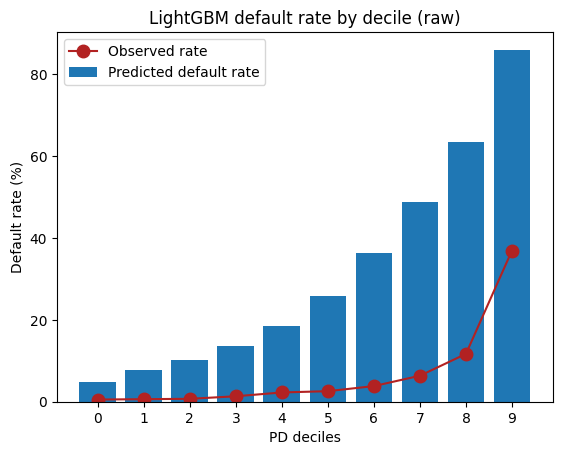

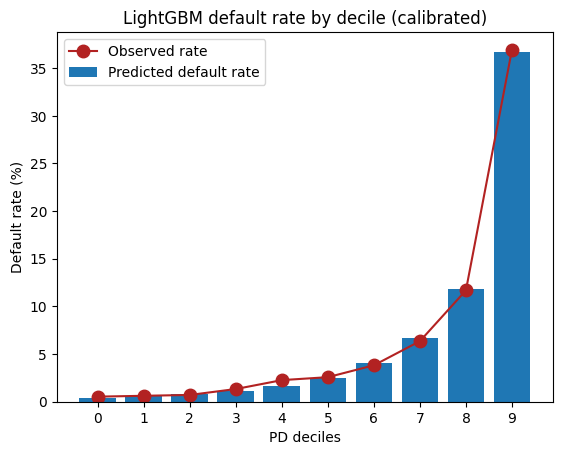

In [11]:
model_config = MODELS[FOCUS_MODEL]
X_test_processed = process_data(model=model_config["type"], X=X_test)

raw_model = joblib.load(model_config["path"])
calibrated_model = joblib.load(MODELS_CALIBRATED[FOCUS_MODEL]["path"])

# save=False: show the plots here, without overwriting the files in calibration/fig/
raw_deciles = evaluate_calibration(
    raw_model, model_config["name"], X_test_processed, y_test, calibrated=False, save=False
)
plt.show()

calibrated_deciles = evaluate_calibration(
    calibrated_model, model_config["name"], X_test_processed, y_test, calibrated=True, save=False
)
plt.show()

In [12]:
# The calibration keeps the order of the customers, so each decile has the
# same customers before and after calibration (same observed rate)
deciles = pd.DataFrame({
    "Predicted raw (%)": raw_deciles["y_pred"] * 100,
    "Predicted calibrated (%)": calibrated_deciles["y_pred"] * 100,
    "Observed (%)": calibrated_deciles["y_obs"] * 100,
    "Observed / predicted (calibrated)": calibrated_deciles["op_ratio"],
})
deciles.round(3)

,Predicted raw (%),Predicted calibrated (%),Observed (%),Observed / predicted (calibrated)
decile,,,,
0,4.879,0.355,0.533,1.502
1,7.683,0.581,0.622,1.072
2,10.259,0.802,0.711,0.887
3,13.591,1.109,1.333,1.202
4,18.431,1.601,2.267,1.416
5,25.843,2.478,2.577,1.040
6,36.262,4.042,3.824,0.946
7,48.743,6.668,6.356,0.953
8,63.375,11.850,11.689,0.986


In the lowest deciles the ratio is less reliable: the default rates are below 2%, so a few defaults more or less change it a lot. What matters most for a credit policy is the agreement in the middle and upper deciles, where approval decisions are made.

## 5. v1 × v2 after calibration

Same comparison as in section 3, now on the **test** set and with the calibrated models.

In [13]:
v1_calibrated_test = pd.read_csv(V1_METRICS_DIR / "calibrated_test_metrics.csv")

compare_versions(v1_calibrated_test, calibrated_test, ["ROC-AUC", "Brier score"]).round(4)

ROC-AUC                 Brier score                
                         v1      v2 v2 - v1          v1      v2 v2 - v1
Model                                                                  
Logistic Regression  0.8160  0.8569  0.0410      0.0532  0.0500 -0.0032
Random Forest        0.8603  0.8604  0.0000      0.0495  0.0497  0.0001
CatBoost             0.8607  0.8606 -0.0001      0.0497  0.0496 -0.0001
XGBoost              0.8618  0.8624  0.0007      0.0496  0.0496  0.0000
LightGBM             0.8634  0.8625 -0.0009      0.0488  0.0489  0.0001

**Reading:**

- The test set confirms the validation results: Logistic Regression gains about 0.04 in AUC, and its calibrated Brier score improves from 0.0532 to 0.0500.
- The ensembles do not change, before or after calibration.
- After calibration, all five models have a Brier score between 0.049 and 0.050.

## 6. Conclusions

- **The v2 preprocessing mainly benefits Logistic Regression.** It gains about 0.04 in AUC and KS, on validation and on test, and its calibrated Brier score improves. The ensembles are not affected: they already handled the extreme values with their splits.
- **The four ensembles are practically tied.** AUC 0.868–0.871 on validation and 0.860–0.863 on test; calibrated Brier score 0.049–0.050. The differences between them are within the normal variation between samples.
- **Logistic Regression is now close to the ensembles** (about 0.01 AUC below on validation, 0.005 on test) and is much easier to explain.
- **Calibration is required.** The class weighting inflates the raw probabilities about 5 times; after the sigmoid calibration they can be read as PDs, with no loss of ranking.

### Model choice

**Logistic Regression is the chosen model.**

LightGBM is better on every metric, but by little: about 0.006–0.009 in AUC, 0.011–0.013 in KS and 0.001 in calibrated Brier score. In exchange for this small difference, Logistic Regression is **explained directly by its coefficients**: each feature has a single effect, with a fixed sign and size, the same for every customer. This makes it easy to justify a decision to a customer or to a credit committee, and to check that the model behaves as expected.

LightGBM is kept as a **challenger model**: a benchmark of how much a more flexible model could add, and a candidate for further analysis (for example, SHAP values to find non-linear effects that could be added to the Logistic Regression).

In [14]:
log_reg = joblib.load(MODELS["log_reg"]["path"])

# The features are standardized, so each coefficient is the change in the
# log-odds of default when the feature increases by one standard deviation
coefficients = pd.Series(log_reg.coef_[0], index=log_reg.feature_names_in_, name="coefficient")
coefficients.sort_values(key=abs, ascending=False).round(3).to_frame()

,coefficient
Util,0.716
AnyLate,0.418
Age,-0.279
Income,-0.187
Late90,0.168
OpenCred,0.165
LateScore,0.156
RealEstate,0.145
Late60_89,0.117
SpecialCode,0.116


**Reading:** the signs match the business intuition and the EDA.

- Higher credit utilization (`Util`) and any late payment (`AnyLate`) increase the risk; they are the two strongest effects.
- Older customers (`Age`) and higher income (`Income`) have lower risk.
- `SpecialCode` (codes 96/98, 54% default in the EDA) increases the risk; `IncomeMissing` decreases it slightly, in line with the lower default rate of this group in the train set (5.4% vs 7.0%).